In [1]:
import json
from copy import deepcopy
from pathlib import Path

import plotnine as gg
import polars as pl
import seaborn as sns

pl.Config.set_fmt_str_lengths(900)
pl.Config.set_tbl_width_chars(900)


%load_ext autoreload
%autoreload 2

In [2]:
PROJECT_DIR = Path().resolve()
OUTPUT_DIR = PROJECT_DIR / "output"

SELECTED_TEST_RUN_TYPE = "file-stack"
SELECTED_TEST_RUN_ID = "full_2026-07-29_17-24-08"
DATASET_NAME = "Canislupus_CZM_712"

RUN_DIR = OUTPUT_DIR / SELECTED_TEST_RUN_TYPE / SELECTED_TEST_RUN_ID / DATASET_NAME
assert RUN_DIR.exists(), f"Run directory {RUN_DIR} does not exist"

In [3]:
# Load data
datas = []
for file in RUN_DIR.glob("*.json"):
    with file.open("r") as f:
        test_data = json.load(f)
    datas.append(test_data)
    print(f"Loaded test data from {file.name}:")

Loaded test data from test_libtifflerc_effort_z0_s0_p5.json:
Loaded test data from test_libtifflerc_effort_z0_s0_p18.json:
Loaded test data from test_libtifflerc_effort_z0_s1_p12.json:
Loaded test data from test_libtifflerc_effort_z0_s2_p12.json:
Loaded test data from test_libtifflerc_effort_z0_s2_p5.json:
Loaded test data from test_libtifflerc_effort_z0_s2_p18.json:
Loaded test data from test_libtifflerc_effort_z0_s2_p1.json:
Loaded test data from test_libtifflerc_effort_z0_s0_p10.json:
Loaded test data from test_libtifflerc_effort_z0_s0_p14.json:
Loaded test data from test_libtiff_sgilog.json:
Loaded test data from test_libtifflerc_effort_z0_s0_p12.json:
Loaded test data from test_libtifflerc_effort_z0_s1_p10.json:
Loaded test data from test_libtifflerc_effort_z0_s1_p5.json:
Loaded test data from test_libtifflerc_effort_z0_s2_p8.json:
Loaded test data from test_libtifflerc_effort_z0_s2_p16.json:
Loaded test data from test_libtifflerc_effort_z0_s0_p16.json:
Loaded test data from test_

In [4]:
from collections.abc import Mapping, Sequence


def flatten(data, prefix: str = "", sep: str = "__") -> dict:
    flattened = {}

    if isinstance(data, Mapping):
        for key, value in data.items():
            column = f"{prefix}{sep}{key}" if prefix else str(key)
            flattened.update(flatten(value, column, sep))

    elif isinstance(data, Sequence) and not isinstance(data, (str, bytes)):
        for index, value in enumerate(data):
            column = f"{prefix}[{index}]"
            flattened.update(flatten(value, column, sep))

    else:
        flattened[prefix] = data

    return flattened


rows = []
for data in datas:
    row = deepcopy(data)

    # Clean up a bit to reduce noise
    # TODO THIS IS REFACTORED
    # row.pop("array_info")
    # row["baseline_test"].pop("array_info")

    rows.append({**row, **flatten(row)})

df = pl.DataFrame(rows, strict=False)
df


name,id,series,vary_var,vary_value,groupings,dataset_name,dataset_path,start_dt,end_dt,total_time_seconds,config,baseline_test,host,compress_time_seconds,nbytes,nbytes_stored,npixels,bitrate,bitrate_compressed,compression_ratio,space_saving,lossless,extra,groupings__implementation,groupings__subcodec,config__name,config__series,config__vary_var,config__vary_value,config__groupings__implementation,config__groupings__subcodec,config__is_lossless,extra__n_jobs
str,str,str,str,i64,struct[2],str,str,str,str,f64,struct[7],null,str,f64,i64,i64,i64,f64,f64,f64,f64,bool,struct[1],str,str,str,str,str,i64,str,str,bool,i64
"""libtifflerc_effort_z0_s0_p5""","""{""name"":""libtifflerc_effort_z0_s0_p5"",""series"":""tiff-lerc"",""vary_var"":""effort"",""vary_value"":5,""groupings"":{""implementation"":""libtiff/tiffcp"",""subcodec"":""none""},""is_lossless"":true,""extra"":{},""compressor"":[""libtiff.compress"",[""-c"",""lerc:0:s0:p5""],{}]}""","""tiff-lerc""","""effort""",5,"{""libtiff/tiffcp"",""none""}","""Canislupus_CZM_712""","""/dtu/3d-imaging-center/projects/2026_DANFIX_201/analysis/compression/datasets/Canislupus_CZM_712""","""2026-07-29T15:25:13.849099Z""","""2026-07-29T15:25:32.218189Z""",18.369117,"{""libtifflerc_effort_z0_s0_p5"",""tiff-lerc"",""effort"",5,{""libtiff/tiffcp"",""none""},true,{}}",null,"""n-62-12-19""",16.734871,12576198072,10507409228,6288000000,16.000252,13.368205,1.196889,0.1645,true,{16},"""libtiff/tiffcp""","""none""","""libtifflerc_effort_z0_s0_p5""","""tiff-lerc""","""effort""",5,"""libtiff/tiffcp""","""none""",true,16
"""libtifflerc_effort_z0_s0_p18""","""{""name"":""libtifflerc_effort_z0_s0_p18"",""series"":""tiff-lerc"",""vary_var"":""effort"",""vary_value"":18,""groupings"":{""implementation"":""libtiff/tiffcp"",""subcodec"":""none""},""is_lossless"":true,""extra"":{},""compressor"":[""libtiff.compress"",[""-c"",""lerc:0:s0:p18""],{}]}""","""tiff-lerc""","""effort""",18,"{""libtiff/tiffcp"",""none""}","""Canislupus_CZM_712""","""/dtu/3d-imaging-center/projects/2026_DANFIX_201/analysis/compression/datasets/Canislupus_CZM_712""","""2026-07-29T15:33:23.503540Z""","""2026-07-29T15:33:41.861747Z""",18.358219,"{""libtifflerc_effort_z0_s0_p18"",""tiff-lerc"",""effort"",18,{""libtiff/tiffcp"",""none""},true,{}}",null,"""n-62-12-19""",16.704591,12576198072,10507409228,6288000000,16.000252,13.368205,1.196889,0.1645,true,{16},"""libtiff/tiffcp""","""none""","""libtifflerc_effort_z0_s0_p18""","""tiff-lerc""","""effort""",18,"""libtiff/tiffcp""","""none""",true,16
"""libtifflerc_effort_z0_s1_p12""","""{""name"":""libtifflerc_effort_z0_s1_p12"",""series"":""tiff-lerc"",""vary_var"":""effort"",""vary_value"":12,""groupings"":{""implementation"":""libtiff/tiffcp"",""subcodec"":""deflate""},""is_lossless"":true,""extra"":{},""compressor"":[""libtiff.compress"",[""-c"",""lerc:0:s1:p12""],{}]}""","""tiff-lerc""","""effort""",12,"{""libtiff/tiffcp"",""deflate""}","""Canislupus_CZM_712""","""/dtu/3d-imaging-center/projects/2026_DANFIX_201/analysis/compression/datasets/Canislupus_CZM_712""","""2026-07-29T15:29:15.271373Z""","""2026-07-29T15:30:02.807140Z""",47.535776,"{""libtifflerc_effort_z0_s1_p12"",""tiff-lerc"",""effort"",12,{""libtiff/tiffcp"",""deflate""},true,{}}",null,"""n-62-12-19""",45.922142,12576198072,10202512086,6288000000,16.000252,12.980295,1.232657,0.188744,true,{16},"""libtiff/tiffcp""","""deflate""","""libtifflerc_effort_z0_s1_p12""","""tiff-lerc""","""effort""",12,"""libtiff/tiffcp""","""deflate""",true,16
"""libtifflerc_effort_z0_s2_p12""","""{""name"":""libtifflerc_effort_z0_s2_p12"",""series"":""tiff-lerc"",""vary_var"":""effort"",""vary_value"":12,""groupings"":{""implementation"":""libtiff/tiffcp"",""subcodec"":""zstd""},""is_lossless"":true,""extra"":{},""compressor"":[""libtiff.compress"",[""-c"",""lerc:0:s2:p12""],{}]}""","""tiff-lerc""","""effort""",12,"{""libtiff/tiffcp"",""zstd""}","""Canislupus_CZM_712""","""/dtu/3d-imaging-center/projects/2026_DANFIX_201/analysis/compression/datasets/Canislup

In [5]:
### File-stack
# Name some columns
# df = df.with_columns(pl.col("compressor").alias("serializer"))

if "baseline_test__compress_time_seconds" in df.columns:
    df = df.with_columns(
        (
            pl.col("baseline_test__compress_time_seconds")
            / pl.col("baseline_test__compress_time_seconds").mean()
        ).alias("baseline_test__compress_time_seconds_relative")
    )

    # Get std
    compress_time_rel_std = df["baseline_test__compress_time_seconds_relative"].std()

    # Compute error intervals
    df = df.with_columns(
        (pl.col("compress_time_seconds") * compress_time_rel_std).alias(
            "compress_time_seconds_std"
        ),
    )


In [6]:
# # Name some columns
# df = df.with_columns(pl.col("config__serializer[0]").alias("serializer"))

# df = df.with_columns(
#     (
#         pl.col("baseline_test__compress_time_seconds")
#         / pl.col("baseline_test__compress_time_seconds").mean()
#     ).alias("baseline_test__compress_time_seconds_relative")
# )

# # Get std
# compress_time_rel_std = df["baseline_test__compress_time_seconds_relative"].std()

# # Compute error intervals
# df = df.with_columns(
#     (pl.col("compress_time_seconds") * compress_time_rel_std).alias(
#         "compress_time_seconds_std"
#     ),
# )


In [7]:
# # Baseline variability
# sns.violinplot(df.to_pandas(), x="baseline_test__compress_time_seconds_relative")

<Axes: xlabel='compress_time_seconds', ylabel='compression_ratio'>

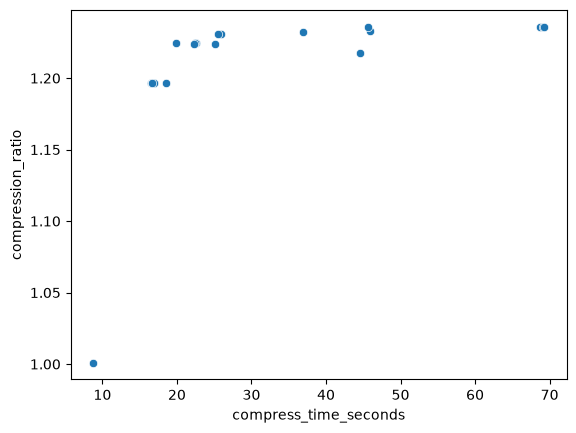

In [8]:
sns.scatterplot(df.to_pandas(), x="compress_time_seconds", y="compression_ratio")

In [9]:
df

name,id,series,vary_var,vary_value,groupings,dataset_name,dataset_path,start_dt,end_dt,total_time_seconds,config,baseline_test,host,compress_time_seconds,nbytes,nbytes_stored,npixels,bitrate,bitrate_compressed,compression_ratio,space_saving,lossless,extra,groupings__implementation,groupings__subcodec,config__name,config__series,config__vary_var,config__vary_value,config__groupings__implementation,config__groupings__subcodec,config__is_lossless,extra__n_jobs
str,str,str,str,i64,struct[2],str,str,str,str,f64,struct[7],null,str,f64,i64,i64,i64,f64,f64,f64,f64,bool,struct[1],str,str,str,str,str,i64,str,str,bool,i64
"""libtifflerc_effort_z0_s0_p5""","""{""name"":""libtifflerc_effort_z0_s0_p5"",""series"":""tiff-lerc"",""vary_var"":""effort"",""vary_value"":5,""groupings"":{""implementation"":""libtiff/tiffcp"",""subcodec"":""none""},""is_lossless"":true,""extra"":{},""compressor"":[""libtiff.compress"",[""-c"",""lerc:0:s0:p5""],{}]}""","""tiff-lerc""","""effort""",5,"{""libtiff/tiffcp"",""none""}","""Canislupus_CZM_712""","""/dtu/3d-imaging-center/projects/2026_DANFIX_201/analysis/compression/datasets/Canislupus_CZM_712""","""2026-07-29T15:25:13.849099Z""","""2026-07-29T15:25:32.218189Z""",18.369117,"{""libtifflerc_effort_z0_s0_p5"",""tiff-lerc"",""effort"",5,{""libtiff/tiffcp"",""none""},true,{}}",null,"""n-62-12-19""",16.734871,12576198072,10507409228,6288000000,16.000252,13.368205,1.196889,0.1645,true,{16},"""libtiff/tiffcp""","""none""","""libtifflerc_effort_z0_s0_p5""","""tiff-lerc""","""effort""",5,"""libtiff/tiffcp""","""none""",true,16
"""libtifflerc_effort_z0_s0_p18""","""{""name"":""libtifflerc_effort_z0_s0_p18"",""series"":""tiff-lerc"",""vary_var"":""effort"",""vary_value"":18,""groupings"":{""implementation"":""libtiff/tiffcp"",""subcodec"":""none""},""is_lossless"":true,""extra"":{},""compressor"":[""libtiff.compress"",[""-c"",""lerc:0:s0:p18""],{}]}""","""tiff-lerc""","""effort""",18,"{""libtiff/tiffcp"",""none""}","""Canislupus_CZM_712""","""/dtu/3d-imaging-center/projects/2026_DANFIX_201/analysis/compression/datasets/Canislupus_CZM_712""","""2026-07-29T15:33:23.503540Z""","""2026-07-29T15:33:41.861747Z""",18.358219,"{""libtifflerc_effort_z0_s0_p18"",""tiff-lerc"",""effort"",18,{""libtiff/tiffcp"",""none""},true,{}}",null,"""n-62-12-19""",16.704591,12576198072,10507409228,6288000000,16.000252,13.368205,1.196889,0.1645,true,{16},"""libtiff/tiffcp""","""none""","""libtifflerc_effort_z0_s0_p18""","""tiff-lerc""","""effort""",18,"""libtiff/tiffcp""","""none""",true,16
"""libtifflerc_effort_z0_s1_p12""","""{""name"":""libtifflerc_effort_z0_s1_p12"",""series"":""tiff-lerc"",""vary_var"":""effort"",""vary_value"":12,""groupings"":{""implementation"":""libtiff/tiffcp"",""subcodec"":""deflate""},""is_lossless"":true,""extra"":{},""compressor"":[""libtiff.compress"",[""-c"",""lerc:0:s1:p12""],{}]}""","""tiff-lerc""","""effort""",12,"{""libtiff/tiffcp"",""deflate""}","""Canislupus_CZM_712""","""/dtu/3d-imaging-center/projects/2026_DANFIX_201/analysis/compression/datasets/Canislupus_CZM_712""","""2026-07-29T15:29:15.271373Z""","""2026-07-29T15:30:02.807140Z""",47.535776,"{""libtifflerc_effort_z0_s1_p12"",""tiff-lerc"",""effort"",12,{""libtiff/tiffcp"",""deflate""},true,{}}",null,"""n-62-12-19""",45.922142,12576198072,10202512086,6288000000,16.000252,12.980295,1.232657,0.188744,true,{16},"""libtiff/tiffcp""","""deflate""","""libtifflerc_effort_z0_s1_p12""","""tiff-lerc""","""effort""",12,"""libtiff/tiffcp""","""deflate""",true,16
"""libtifflerc_effort_z0_s2_p12""","""{""name"":""libtifflerc_effort_z0_s2_p12"",""series"":""tiff-lerc"",""vary_var"":""effort"",""vary_value"":12,""groupings"":{""implementation"":""libtiff/tiffcp"",""subcodec"":""zstd""},""is_lossless"":true,""extra"":{},""compressor"":[""libtiff.compress"",[""-c"",""lerc:0:s2:p12""],{}]}""","""tiff-lerc""","""effort""",12,"{""libtiff/tiffcp"",""zstd""}","""Canislupus_CZM_712""","""/dtu/3d-imaging-center/projects/2026_DANFIX_201/analysis/compression/datasets/Canislup

In [ ]:
df = df.with_columns(pl.col("config__groupings__subcodec").replace("NaN", "none"))

In [11]:
print(df[["name", "config__groupings__subcodec"]])

shape: (26, 2)
┌──────────────────────────────┬─────────────────────────────┐
│ name                         ┆ config__groupings__subcodec │
│ ---                          ┆ ---                         │
│ str                          ┆ str                         │
╞══════════════════════════════╪═════════════════════════════╡
│ libtifflerc_effort_z0_s0_p5  ┆ none                        │
│ libtifflerc_effort_z0_s0_p18 ┆ none                        │
│ libtifflerc_effort_z0_s1_p12 ┆ deflate                     │
│ libtifflerc_effort_z0_s2_p12 ┆ zstd                        │
│ libtifflerc_effort_z0_s2_p5  ┆ zstd                        │
│ …                            ┆ …                           │
│ libtifflerc_effort_z0_s2_p10 ┆ zstd                        │
│ libtifflerc_effort_z0_s0_p22 ┆ none                        │
│ libtifflerc_effort_z0_s0_p20 ┆ none                        │
│ libtifflerc_effort_z0_s0_p8  ┆ none                        │
│ libtifflerc_effort_z0_s0_p1  ┆ none   

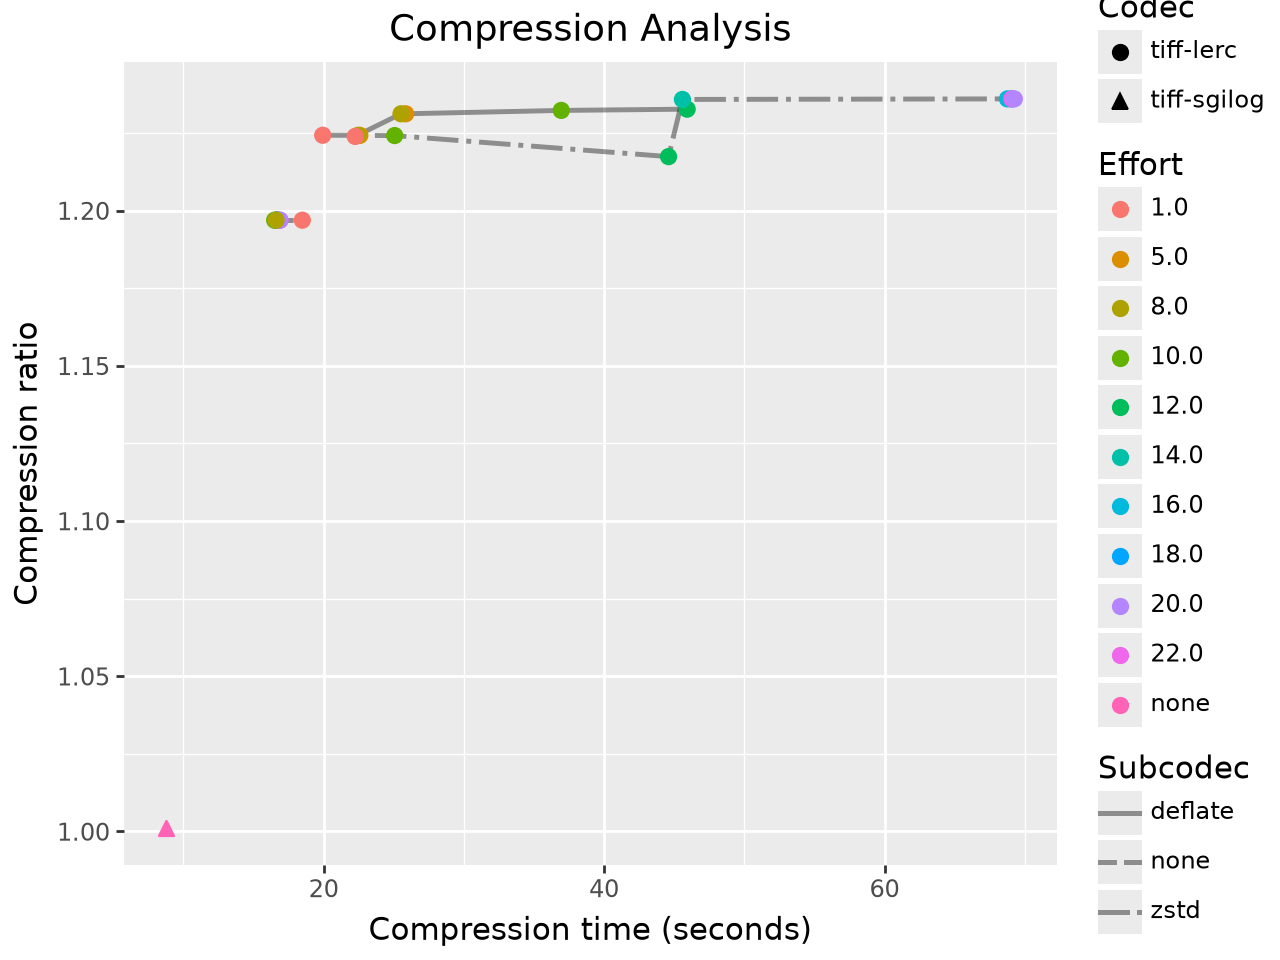

In [26]:
(
    gg.ggplot(df.to_pandas().fillna("none"))
    + gg.aes(
        "compress_time_seconds",
        "compression_ratio",
        shape="series",
        color="factor(vary_value)",
        linetype="config__groupings__subcodec",
        group="series + config__groupings__subcodec",
    )
    + gg.geom_line(color="black", alpha=0.4, size=1)
    + gg.geom_point(size=2.5)
    # + gg.geom_text(aes=gg.aes(adjust_text={"arrowprops": {"arrowstyle": "->"}})
    # + gg.aes(
    #     xmin="compress_time_seconds-compress_time_seconds_std",
    #     xmax="compress_time_seconds+compress_time_seconds_std",
    # )
    # + gg.geom_errorbarh(height=0.02)
    + gg.labs(
        title="Compression Analysis",
        x="Compression time (seconds)",
        y="Compression ratio",
    )
    + gg.scale_shape_discrete(name="Codec")
    + gg.scale_color_discrete(name="Effort")
    + gg.scale_linetype_discrete(name="Subcodec")
    # + gg.theme_xkcd()
)

In [13]:
(
    gg.ggplot(df)
    + gg.aes(
        "compress_time_seconds",
        "compression_ratio",
        shape="serializer",
        color="factor(vary_value)",
        group="series",
    )
    + gg.geom_point()
    + gg.geom_line()
    + gg.aes(
        xmin="compress_time_seconds-compress_time_seconds_std",
        xmax="compress_time_seconds+compress_time_seconds_std",
    )
    + gg.geom_errorbarh(height=0.02)
    + gg.labs(
        title="Compression Analysis",
        x="Compression time (seconds)",
        y="Compression ratio",
    )
    + gg.scale_shape_discrete(name="Codec")
    + gg.scale_color_discrete(name="Effort")
    # + gg.theme_xkcd()
)

PlotnineError: "Could not evaluate the 'shape' mapping: 'serializer' (original error: name 'serializer' is not defined)"